Conduct rigorous comparative analysis of baseline classification models (logistic regression, decision trees, SVM, KNN), assessing performance metrics, interpretability, and computational efficiency to inform model selection.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 500

In [4]:
age = np.random.normal(55, 12, n_samples).clip(20, 85)
bmi = np.random.normal(28, 5, n_samples).clip(15, 45)
blood_pressure = np.random.normal(130, 18, n_samples).clip(90, 190)
glucose = np.random.normal(110, 30, n_samples).clip(70, 250)

In [6]:
risk_logits = (
    0.05 * (age - 55) 
    + 0.12 * (bmi - 28) 
    + 0.03 * (blood_pressure - 130) 
    + 0.04 * (glucose - 110)
    + 0.002 * (bmi - 28) * (glucose - 110) 
)

In [7]:
probs = 1 / (1 + np.exp(-risk_logits))
target = (probs > np.median(probs)).astype(int)

In [8]:
df_benchmark = pd.DataFrame({
    'age': age.round(1),
    'bmi': bmi.round(1),
    'blood_pressure': blood_pressure.round(1),
    'glucose': glucose.round(1),
    'risk_level': target
})

In [9]:
print("Dataset shape:", df_benchmark.shape)
print("Class distribution:\n", df_benchmark['risk_level'].value_counts())

Dataset shape: (500, 5)
Class distribution:
 risk_level
1    250
0    250
Name: count, dtype: int64


In [10]:
import time
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [11]:
X = df_benchmark[['age', 'bmi', 'blood_pressure', 'glucose']]
y = df_benchmark['risk_level']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [13]:
candidate_models = {
    'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(random_state=42))]),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'SVM (RBF Kernel)': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', probability=True, random_state=42))]),
    'K-Nearest Neighbors': Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=7))])
}

In [14]:
benchmark_results = []

In [17]:
for name, model in candidate_models.items():
    t0_train = time.perf_counter()
    model.fit(X_train, y_train)
    t1_train = time.perf_counter()
    fit_time_ms = (t1_train - t0_train) * 1000

    t0_infer = time.perf_counter()
    y_pred = model.predict(X_test)
    t1_infer = time.perf_counter()
    infer_time_ms = (t1_infer - t0_infer) * 1000

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_proba = model.decision_function(X_test)

    benchmark_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Fit Time (ms)': round(fit_time_ms, 3),
        'Inference Time (ms)': round(infer_time_ms, 3)
    })

In [18]:
df_metrics = pd.DataFrame(benchmark_results).set_index('Model')
print("--- Baseline Classification Benchmark Summary ---")
print(df_metrics.round(4))

--- Baseline Classification Benchmark Summary ---
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC  \
Model                                                                 
Logistic Regression     0.960     0.9672  0.9516    0.9593   0.9931   
Decision Tree           0.776     0.7833  0.7581    0.7705   0.8410   
SVM (RBF Kernel)        0.944     0.9508  0.9355    0.9431   0.9931   
K-Nearest Neighbors     0.912     0.9048  0.9194    0.9120   0.9766   
Logistic Regression     0.960     0.9672  0.9516    0.9593   0.9931   
Decision Tree           0.776     0.7833  0.7581    0.7705   0.8410   
SVM (RBF Kernel)        0.944     0.9508  0.9355    0.9431   0.9931   
K-Nearest Neighbors     0.912     0.9048  0.9194    0.9120   0.9766   

                     Fit Time (ms)  Inference Time (ms)  
Model                                                    
Logistic Regression        155.432                1.909  
Decision Tree                9.026                2.007  
SVM (RB

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

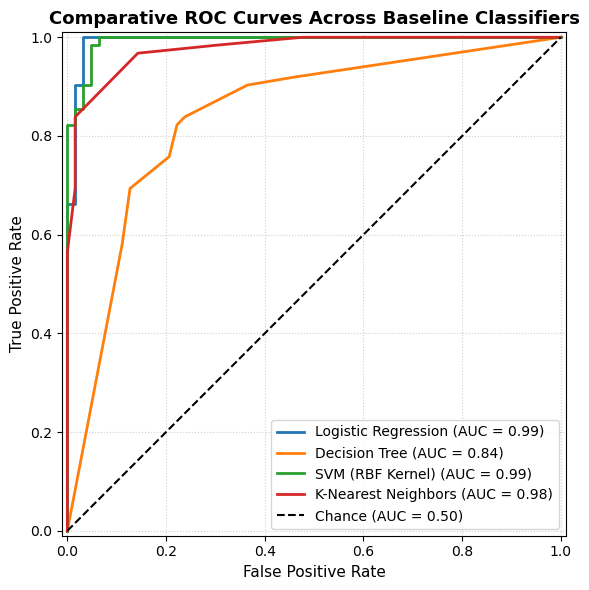

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))

for name, model in candidate_models.items():
    RocCurveDisplay.from_estimator(
        model, 
        X_test, 
        y_test, 
        name=name, 
        ax=ax, 
        linewidth=2
    )

ax.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.50)')
ax.set_title('Comparative ROC Curves Across Baseline Classifiers', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [21]:
tradeoff_data = {
    'Model': ['Logistic Regression', 'Decision Tree', 'SVM (RBF Kernel)', 'K-Nearest Neighbors'],
    'Interpretability': ['High (Odds Ratios / Betas)', 'High (Visual Split Rules)', 'Low (Black-Box Kernel)', 'Low (Distance Instance-Based)'],
    'Scalability (N Samples)': ['High O(N)', 'High O(N log N)', 'Low O(N^2 to N^3)', 'Low O(N) Inference'],
    'Linearity Assumption': ['Yes (Log-Odds)', 'No (Non-Linear)', 'No (Non-Linear)', 'No (Non-Linear)'],
    'Best Use Case': ['Baseline risk scoring & linear feature attribution', 'Explaining operational rules to non-technical stakeholders', 'Complex non-linear boundaries where latency is not critical', 'Small datasets with uniform features and zero training cost']
}

In [22]:
df_tradeoffs = pd.DataFrame(tradeoff_data).set_index('Model')

In [23]:
print("--- Multi-Criteria Model Selection Matrix ---")
for idx, row in df_tradeoffs.iterrows():
    print(f"\n[{idx}]")
    print(f"  • Interpretability : {row['Interpretability']}")
    print(f"  • Scalability      : {row['Scalability (N Samples)']}")
    print(f"  • Assumptions      : Linearity = {row['Linearity Assumption']}")
    print(f"  • Primary Use Case : {row['Best Use Case']}")

--- Multi-Criteria Model Selection Matrix ---

[Logistic Regression]
  • Interpretability : High (Odds Ratios / Betas)
  • Scalability      : High O(N)
  • Assumptions      : Linearity = Yes (Log-Odds)
  • Primary Use Case : Baseline risk scoring & linear feature attribution

[Decision Tree]
  • Interpretability : High (Visual Split Rules)
  • Scalability      : High O(N log N)
  • Assumptions      : Linearity = No (Non-Linear)
  • Primary Use Case : Explaining operational rules to non-technical stakeholders

[SVM (RBF Kernel)]
  • Interpretability : Low (Black-Box Kernel)
  • Scalability      : Low O(N^2 to N^3)
  • Assumptions      : Linearity = No (Non-Linear)
  • Primary Use Case : Complex non-linear boundaries where latency is not critical

[K-Nearest Neighbors]
  • Interpretability : Low (Distance Instance-Based)
  • Scalability      : Low O(N) Inference
  • Assumptions      : Linearity = No (Non-Linear)
  • Primary Use Case : Small datasets with uniform features and zero trainin